# Semantic Scholar enrichment

Recorded references per ogbn-arxiv paper before and after the enrichment with Semantic Scholar
citation records (Section 4.2 of the thesis), and the figure `diagrams/enrichment_degree.pdf`.
A paper counts as covered if Semantic Scholar added at least one citation to it.

Inputs: the joint graph (`data/processed/joint/`), the ogbn-arxiv edges and the filtered
Semantic Scholar records. The data is not included in this repository.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, ".")
import thesis_style as ts
ts.apply()

nodes = pd.read_csv("../data/processed/joint/nodes.csv", usecols=["node_id", "mag_id", "core"])
joint_edges = pd.read_csv("../data/processed/joint/edges.csv")
ogbn_edges = pd.read_csv("../data/raw/ogbn_arxiv/edges.csv")
s2_papers = pd.read_parquet("../data/processed/s2/papers_filtered.parquet", columns=["mag_id"])

ogbn = nodes[nodes["core"]]
ids = ogbn["node_id"].values
before = ogbn_edges.groupby("src_node_id").size().reindex(ids, fill_value=0)
after = joint_edges[joint_edges["src_node_id"].isin(ids)].groupby("src_node_id").size().reindex(ids, fill_value=0)
covered = after > before
has_record = ogbn["mag_id"].isin(set(s2_papers["mag_id"])).values

## Statistics

In [2]:
def row(name, b, a):
    return {"property of ogbn-arxiv papers": name, "before": b, "after": a}

table = pd.DataFrame([
    row("mean recorded references", round(before.mean(), 2), round(after.mean(), 2)),
    row("median recorded references", before.median(), after.median()),
    row("papers with no recorded reference", int((before == 0).sum()), int((after == 0).sum())),
    row("papers with more than 50 recorded references", int((before > 50).sum()), int((after > 50).sum())),
])
print(table.to_string(index=False))
print()
print(f"ogbn-arxiv papers: {len(ids):,}; joint graph: {len(nodes):,} papers ({(~nodes['core']).sum():,} added), {len(joint_edges):,} edges")
print(f"covered (Semantic Scholar added >= 1 citation): {covered.sum():,} ({covered.mean():.1%}), mean after {after[covered].mean():.2f}")
print(f"not covered: {(~covered).sum():,} ({(~covered).mean():.1%}), mean after {after[~covered].mean():.2f}")
print(f"has a usable Semantic Scholar record (MAG id + abstract): {has_record.sum():,} ({has_record.mean():.1%})")
print(f"  of which no citation added: {(has_record & ~covered.values).sum():,}")
print(f"covered but no usable record: {(~has_record & covered.values).sum():,}")

src_ogbn = joint_edges[joint_edges["src_node_id"].isin(ids)]
to_added = (~src_ogbn["dst_node_id"].isin(ids)).sum()
print(f"edges from ogbn-arxiv papers: before {len(ogbn_edges):,}, after {len(src_ogbn):,}; "
      f"to added papers {to_added:,}; new ogbn->ogbn {len(src_ogbn) - to_added - len(ogbn_edges):,}")
print(f"edges from added papers: {len(joint_edges) - len(src_ogbn):,}")
print(f"share of ogbn-arxiv papers with more than 60 recorded references: before {(before > 60).mean():.2%}, after {(after > 60).mean():.2%}")

               property of ogbn-arxiv papers   before   after
                    mean recorded references     6.89   12.55
                  median recorded references     4.00    8.00
           papers with no recorded reference 17440.00 8675.00
papers with more than 50 recorded references   499.00 4284.00

ogbn-arxiv papers: 169,343; joint graph: 384,756 papers (215,413 added), 3,844,151 edges
covered (Semantic Scholar added >= 1 citation): 94,756 (56.0%), mean after 17.00
not covered: 74,587 (44.0%), mean after 6.90
has a usable Semantic Scholar record (MAG id + abstract): 98,811 (58.3%)
  of which no citation added: 4,055
covered but no usable record: 0
edges from ogbn-arxiv papers: before 1,166,243, after 2,125,355; to added papers 889,024; new ogbn->ogbn 70,088
edges from added papers: 1,718,796
share of ogbn-arxiv papers with more than 60 recorded references: before 0.16%, after 1.34%


## Figure

Recorded references per paper: (a) before and after the enrichment; (b) after the enrichment, by coverage. The last bin collects papers with 60 or more references.

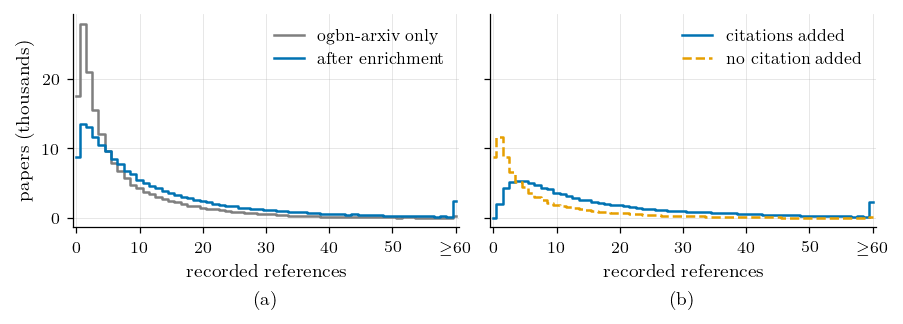

In [3]:
CAP = 60
bins = np.arange(0, CAP + 2) - 0.5

def counts(x):
    return np.histogram(np.minimum(x, CAP), bins=bins)[0] / 1000

fig, axes = plt.subplots(1, 2, figsize=(ts.TEXTWIDTH, 52 * ts.MM), sharey=True, layout="constrained")
x = np.arange(0, CAP + 1)

ax = axes[0]
ax.step(x, counts(before), where="mid", color=ts.COLORS["grey"], label="ogbn-arxiv only")
ax.step(x, counts(after), where="mid", color=ts.COLORS["blue"], label="after enrichment")
ax.set_title("(a)", y=-0.42)

ax = axes[1]
ax.step(x, counts(after[covered]), where="mid", color=ts.COLORS["blue"], label="citations added")
ax.step(x, counts(after[~covered]), where="mid", color=ts.COLORS["orange"], linestyle="--", label="no citation added")
ax.set_title("(b)", y=-0.42)

for ax in axes:
    ax.set_xlabel("recorded references")
    ax.set_xlim(-0.5, CAP + 0.5)
    ax.set_xticks([0, 10, 20, 30, 40, 50, 60])
    ax.set_xticklabels(["0", "10", "20", "30", "40", "50", r"$\geq$60"])
    ax.legend(loc="upper right")
axes[0].set_ylabel("papers (thousands)")

ts.save(fig, "enrichment_degree", outdir="../diagrams")